# Market Share Shift Analysis

*Platform and genre market-share movements across four decades of video game sales.*

## Project overview

This project examines how global video game sales were distributed across platforms, genres, publishers, and regions from 1980 through 2019. The analysis is built around SQLite window functions, with pandas handling data preparation and result presentation and matplotlib providing the visual analysis.

The central questions concern platform leadership, changes in genre mix, market concentration, publisher performance, and the difference between North American and Japanese genre preferences.

## Research questions

- Which platforms led each decade, and how did their shares change?
- Which genres gained or lost the most share between the first and final decades?
- How much of each decade's sales belonged to its three leading platforms?
- Where did North American and Japanese genre shares diverge most?
- Which publishers led each decade, and how uneven was publisher performance?

## Analytical roles

SQL performs the aggregations and window calculations: share of total, rankings, period-over-period comparisons, cumulative sales, and moving averages. Python loads the source data, executes the SQL statements, checks the returned results, and creates charts from those query outputs. Market-share calculations remain in SQL rather than being recreated in pandas.

## Dataset and scope

**Source:** [Video Game Sales — Kaggle](https://www.kaggle.com/datasets/gregorut/videogamesales)

The source file contains 16,598 game records and 11 columns, including release year, platform, genre, publisher, regional sales, and global sales. Sales are reported in millions of copies.

The analysis window is 1980–2019, grouped into the 1980s, 1990s, 2000s, and 2010s. The supplied data contains records only through 2017, so the 2010s results represent the available 2010–2017 observations rather than a complete decade. Rows with missing or non-numeric years and rows outside the analysis window are excluded. Missing publisher labels remain in the analysis as an `(unknown)` group.

In [1]:
from pathlib import Path
import re
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# the Desktop dataset is preferred; the project copy supports portable execution
file_path = Path(r"C:\Users\anarrasulzada\Desktop\vgsales.csv")
if not file_path.exists():
    file_path = Path("vgsales.csv")

sql_path = Path("queries.sql")

if not file_path.exists():
    raise FileNotFoundError("vgsales.csv was not found on the Desktop or in the working directory.")
if not sql_path.exists():
    raise FileNotFoundError("queries.sql is not in the notebook's working directory.")

raw = pd.read_csv(file_path)

print(f"Dataset: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())


Dataset: 16,598 rows × 11 columns


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## Initial data inspection

The year field defines the analytical periods. Sales columns are numeric, while text labels are normalized for consistent grouping. Missing platform, genre, and publisher labels are retained as explicit unknown categories in SQL.

In [2]:
raw.columns = raw.columns.str.strip()

sales_columns = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
text_columns = ["Name", "Platform", "Genre", "Publisher"]

for column in sales_columns:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")

for column in text_columns:
    raw[column] = raw[column].astype("string").str.strip().replace("", pd.NA)

year_numeric = pd.to_numeric(raw["Year"], errors="coerce")

print("Normalized column types:")
display(raw.dtypes.to_frame("dtype"))

print("Missing values in the source file:")
display(raw.isna().sum().to_frame("missing_rows").sort_values("missing_rows", ascending=False))

Normalized column types:


,dtype
Rank,int64
Name,string[python]
Platform,string[python]
Year,float64
Genre,string[python]
Publisher,string[python]
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


Missing values in the source file:


,missing_rows
Year,271
Publisher,58
Rank,0
Platform,0
Name,0
Genre,0
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


## Analysis window and row exclusions

The year filter separates missing or non-numeric values, non-integer years, and integer years outside 1980–2019. Global sales are also checked because they form the denominator for the global market-share calculations. In this dataset, the retained observations cover 1980–2017.

In [3]:
original_rows = len(raw)
missing_or_non_numeric_years = int(year_numeric.isna().sum())
non_integer_year_mask = year_numeric.notna() & (year_numeric % 1 != 0)
non_integer_years = int(non_integer_year_mask.sum())
integer_year_mask = year_numeric.notna() & (year_numeric % 1 == 0)
outside_period_mask = integer_year_mask & ~year_numeric.between(1980, 2019)
outside_period_years = int(outside_period_mask.sum())
valid_year_mask = integer_year_mask & year_numeric.between(1980, 2019)

prepared = raw.loc[valid_year_mask].copy()
prepared["Year"] = year_numeric.loc[valid_year_mask].astype("int64")

missing_global_sales = int(prepared["Global_Sales"].isna().sum())
prepared = prepared.dropna(subset=["Global_Sales"]).copy()

row_drop_report = pd.DataFrame(
    {
        "stage": [
            "original source rows",
            "missing or non-numeric year",
            "non-integer year",
            "integer year outside 1980–2019",
            "missing global sales within valid years",
            "final analysis rows",
        ],
        "rows": [
            original_rows,
            missing_or_non_numeric_years,
            non_integer_years,
            outside_period_years,
            missing_global_sales,
            len(prepared),
        ],
    }
)

display(row_drop_report)
print(f"Total excluded rows: {original_rows - len(prepared):,}")
print(f"Year coverage after filtering: {prepared['Year'].min()}–{prepared['Year'].max()}")

assert len(prepared) == original_rows - missing_or_non_numeric_years - non_integer_years - outside_period_years - missing_global_sales
assert prepared["Year"].between(1980, 2019).all()
assert prepared["Year"].mod(1).eq(0).all()

,stage,rows
0,original source rows,16598
1,missing or non-numeric year,271
2,non-integer year,0
3,integer year outside 1980–2019,1
4,missing global sales within valid years,0
5,final analysis rows,16326


Total excluded rows: 272
Year coverage after filtering: 1980–2017


## SQLite analysis table

The cleaned rows are loaded into an in-memory SQLite database named `games`. The decade field is derived in SQL with integer arithmetic. SQLite 3.25 or newer is required for the window functions used throughout the query file.

In [4]:
# null text values represented as python nulls for sqlite
for column in text_columns:
    prepared[column] = prepared[column].astype("object").where(prepared[column].notna(), None)

conn = sqlite3.connect(":memory:")
prepared.to_sql("games", conn, index=False, if_exists="replace")

sqlite_version = pd.read_sql_query("select sqlite_version() as sqlite_version", conn).iloc[0, 0]
version_parts = tuple(int(part) for part in sqlite_version.split(".")[:3])

print(f"SQLite version: {sqlite_version}")
print(f"Rows loaded into games: {pd.read_sql_query('select count(*) as row_count from games', conn).iloc[0, 0]:,}")

if version_parts < (3, 25, 0):
    raise RuntimeError("SQLite 3.25.0 or newer is required for window functions.")

conn.execute("alter table games add column decade integer")
conn.execute("update games set decade = cast((Year / 10) * 10 as integer)")

decade_counts = pd.read_sql_query(
    "select decade, count(*) as game_rows from games group by decade order by decade",
    conn,
)
display(decade_counts)

assert decade_counts["decade"].tolist() == [1980, 1990, 2000, 2010]

# indexes supporting the main partition and grouping fields
conn.execute("create index idx_games_decade_platform on games(decade, Platform)")
conn.execute("create index idx_games_decade_genre on games(decade, Genre)")
conn.execute("create index idx_games_year_platform on games(Year, Platform)")

SQLite version: 3.46.1
Rows loaded into games: 16,326


,decade,game_rows
0,1980,205
1,1990,1769
2,2000,9208
3,2010,5144


## SQL query execution

The SQL file contains ten required queries and three bonus queries. Each statement is extracted by its query label and executed against the same SQLite table. The returned DataFrames are the source for the result checks, narrative, and charts.

In [5]:
query_ids = ["q1", "q2", "q3", "q4", "q5", "q6", "q7", "q8", "q9", "q10", "b1", "b2", "b3"]
sql_text = sql_path.read_text(encoding="utf-8")

def get_query(query_id):
    pattern = rf"(?ms)^-- {query_id} \|[^\n]*\n(.*?;)"
    match = re.search(pattern, sql_text)
    if match is None:
        raise KeyError(f"Query label not found: {query_id}")
    return match.group(1).strip()

query_results = {
    query_id: pd.read_sql_query(get_query(query_id), conn)
    for query_id in query_ids
}

q1 = query_results["q1"]
q2 = query_results["q2"]
q3 = query_results["q3"]
q4 = query_results["q4"]
q5 = query_results["q5"]
q6 = query_results["q6"]
q7 = query_results["q7"]
q8 = query_results["q8"]
q9 = query_results["q9"]
q10 = query_results["q10"]
b1 = query_results["b1"]
b2 = query_results["b2"]
b3 = query_results["b3"]

query_summary = pd.DataFrame(
    {
        "query": query_ids,
        "rows_returned": [len(query_results[query_id]) for query_id in query_ids],
    }
)
display(query_summary)

def show_result(result, preview_rows=15):
    print(f"Rows returned: {len(result):,}")
    if len(result) <= preview_rows:
        display(result)
    else:
        display(result.head(preview_rows))
        print("The complete result remains available in its DataFrame.")

,query,rows_returned
0,q1,48
1,q2,20
2,q3,40
3,q4,93
4,q5,240
5,q6,47
6,q7,2
7,q8,47
8,q9,4
9,q10,4


## Result validation

The checks cover decade shares, top-five ranking counts, non-empty rank-gap examples, period comparisons, cumulative sales, regional denominators, and the bonus calendar-year moving-average grid. Rounded percentage totals may differ from 100 by a few hundredths of a point.

In [6]:
platform_share_totals = q1.groupby("decade")["market_share_pct"].sum()
genre_share_totals = q6.groupby("decade")["genre_share_pct"].sum()
regional_share_totals = q8.groupby("decade")[["na_share_pct", "jp_share_pct"]].sum()
cumulative_is_monotonic = q5.groupby("platform")["cumulative_sales_m"].apply(
    lambda values: values.is_monotonic_increasing
)

assert np.allclose(platform_share_totals.values, 100, atol=0.05)
assert np.allclose(genre_share_totals.values, 100, atol=0.05)
assert np.allclose(regional_share_totals.values, 100, atol=0.05)
assert q2.groupby("decade").size().eq(5).all()
assert q3["rank_gap"].gt(0).any()
assert q4["previous_decade"].notna().all()
assert cumulative_is_monotonic.all()
assert q9["top_three_share_pct"].between(0, 100).all()
assert b2.groupby("platform").size().eq(40).all()
assert b3["platform"].is_unique

validation_summary = pd.DataFrame(
    {
        "check": [
            "platform share totals by decade",
            "genre share totals by decade",
            "regional share totals by decade",
            "five platforms returned per decade",
            "rank and dense_rank difference present",
            "cumulative sales are non-decreasing",
            "three-year calendar grid contains 40 years per platform",
            "one lifecycle row per platform",
        ],
        "status": ["passed"] * 8,
    }
)
display(validation_summary)

,check,status
0,platform share totals by decade,passed
1,genre share totals by decade,passed
2,regional share totals by decade,passed
3,five platforms returned per decade,passed
4,rank and dense_rank difference present,passed
5,cumulative sales are non-decreasing,passed
6,three-year calendar grid contains 40 years per...,passed
7,one lifecycle row per platform,passed


## Platform share by decade

`sum() over (partition by decade)` adds the decade total to each platform row without collapsing the platform-level result. The denominator is calculated from the grouped platform sales, so no totals self-join is required.

In [7]:
show_result(q1, preview_rows=20)

platform_leaders = (
    q1.sort_values(["decade", "market_share_pct"], ascending=[True, False])
    .groupby("decade", as_index=False)
    .head(1)
)
display(platform_leaders)

Rows returned: 48


,decade,platform,platform_sales_m,decade_total_m,market_share_pct
0,1980,NES,223.52,376.58,59.36
1,1980,2600,86.57,376.58,22.99
2,1980,GB,66.41,376.58,17.64
3,1980,PC,0.06,376.58,0.02
4,1980,DS,0.02,376.58,0.01
5,1990,PS,586.85,1278.91,45.89
6,1990,SNES,200.05,1278.91,15.64
7,1990,N64,180.86,1278.91,14.14
8,1990,GB,159.01,1278.91,12.43
9,1990,PC,49.98,1278.91,3.91


The complete result remains available in its DataFrame.


,decade,platform,platform_sales_m,decade_total_m,market_share_pct
0,1980,NES,223.52,376.58,59.36
5,1990,PS,586.85,1278.91,45.89
21,2000,PS2,1227.36,4644.02,26.43
36,2010,PS3,602.44,2520.56,23.90


### Top five platforms within each decade

`rank()` preserves ties in the sales ranking. `row_number()` supplies a deterministic selection order, and the outer query filters the result to five rows per decade.

In [8]:
show_result(q2, preview_rows=25)

Rows returned: 20


,decade,platform,platform_sales_m,sales_rank,selection_order
0,1980,NES,223.52,1,1
1,1980,2600,86.57,2,2
2,1980,GB,66.41,3,3
3,1980,PC,0.06,4,4
4,1980,DS,0.02,5,5
5,1990,PS,586.85,1,1
6,1990,SNES,200.05,2,2
7,1990,N64,180.86,3,3
8,1990,GB,159.01,4,4
9,1990,PC,49.98,5,5


### Ranking semantics: RANK, DENSE_RANK, and ROW_NUMBER

`rank()` assigns the same position to tied values and leaves a gap after the tie. `dense_rank()` assigns the same position without a gap. `row_number()` assigns a unique sequence to every row, including tied values. The query returns rows where the first two ranking functions differ.

In [9]:
show_result(q3, preview_rows=12)

Rows returned: 40


,decade,game_name,platform,global_sales_m,games_with_same_sales,rank_position,dense_rank_position,rank_gap,row_number_position
0,1980,Tennis,NES,2.17,1,32,31,1,32
1,1980,Volleyball,NES,2.15,1,33,32,1,33
2,1980,Mahjong,NES,2.14,2,34,33,1,34
3,1980,R.C. Pro-Am,NES,2.14,2,34,33,1,35
4,1980,Demon Attack,2600,2.13,1,36,34,2,36
5,1980,Golf,GB,2.12,1,37,35,2,37
6,1980,Tennis,GB,1.99,1,38,36,2,38
7,1980,E.T.: The Extra Terrestrial,2600,1.97,1,39,37,2,39
8,1980,Rad Racer,NES,1.96,2,40,38,2,40
9,1980,Soccer,NES,1.96,2,40,38,2,41


The complete result remains available in its DataFrame.


## Platform share changes between consecutive decades

A complete platform-by-decade grid represents missing platform-decade combinations with zero sales. `lag()` therefore compares adjacent calendar decades, rather than the previous decade in which a platform happened to record sales.

In [10]:
show_result(q4, preview_rows=18)

largest_platform_gain = q4.loc[q4["share_change_pp"].idxmax()]
largest_platform_loss = q4.loc[q4["share_change_pp"].idxmin()]
display(pd.DataFrame([largest_platform_gain, largest_platform_loss]))

Rows returned: 93


,decade,previous_decade,platform,share_now_pct,share_previous_pct,share_change_pp
0,1990,1980,PS,45.89,0.00,45.89
1,1990,1980,SNES,15.64,0.00,15.64
2,1990,1980,N64,14.14,0.00,14.14
3,1990,1980,PC,3.91,0.02,3.89
4,1990,1980,SAT,2.63,0.00,2.63
5,1990,1980,GEN,2.22,0.00,2.22
6,1990,1980,DC,0.67,0.00,0.67
7,1990,1980,SCD,0.15,0.00,0.15
8,1990,1980,NG,0.11,0.00,0.11
9,1990,1980,WS,0.04,0.00,0.04


The complete result remains available in its DataFrame.


,decade,previous_decade,platform,share_now_pct,share_previous_pct,share_change_pp
0,1990,1980,PS,45.89,0.00,45.89
30,1990,1980,NES,2.15,59.36,-57.20


## Cumulative platform sales

The source rows are aggregated to platform-year before the running total is calculated. The explicit frame `rows between unbounded preceding and current row` accumulates each platform's annual sales in chronological order.

In [11]:
show_result(q5, preview_rows=15)

platform_lifetime_sales = (
    q5.groupby("platform", as_index=False)["annual_sales_m"]
    .sum()
    .rename(columns={"annual_sales_m": "lifetime_sales_m"})
    .sort_values("lifetime_sales_m", ascending=False)
)
display(platform_lifetime_sales.head(10))

Rows returned: 240


,year,platform,annual_sales_m,cumulative_sales_m
0,1980,2600,11.38,11.38
1,1981,2600,35.77,47.15
2,1982,2600,28.86,76.01
3,1983,2600,5.83,81.84
4,1984,2600,0.27,82.11
5,1985,2600,0.45,82.56
6,1986,2600,0.66,83.22
7,1987,2600,1.98,85.20
8,1988,2600,0.75,85.95
9,1989,2600,0.62,86.57


The complete result remains available in its DataFrame.


,platform,lifetime_sales_m
16,PS2,1233.46
28,X360,969.61
17,PS3,949.35
26,Wii,909.81
4,DS,818.67
15,PS,727.39
6,GBA,313.56
19,PSP,291.71
18,PS4,278.10
13,PC,255.05


## Genre share by decade

The genre query applies the same share-of-total pattern as the platform query. Global genre shares and platform shares therefore use the same decade-level global-sales denominator.

In [12]:
show_result(q6, preview_rows=18)

genre_leaders = (
    q6.sort_values(["decade", "genre_share_pct"], ascending=[True, False])
    .groupby("decade", as_index=False)
    .head(1)
)
display(genre_leaders)

Rows returned: 47


,decade,genre,genre_sales_m,decade_total_m,genre_share_pct
0,1980,Platform,122.27,376.58,32.47
1,1980,Puzzle,62.73,376.58,16.66
2,1980,Shooter,59.79,376.58,15.88
3,1980,Action,51.18,376.58,13.59
4,1980,Sports,32.28,376.58,8.57
5,1980,Role-Playing,15.25,376.58,4.05
6,1980,Racing,12.10,376.58,3.21
7,1980,Misc,8.45,376.58,2.24
8,1980,Fighting,7.24,376.58,1.92
9,1980,Adventure,4.78,376.58,1.27


The complete result remains available in its DataFrame.


,decade,genre,genre_sales_m,decade_total_m,genre_share_pct
0,1980,Platform,122.27,376.58,32.47
11,1990,Platform,208.91,1278.91,16.34
23,2000,Action,858.91,4644.02,18.49
35,2010,Action,673.50,2520.56,26.72


### Largest genre share gain and loss

`first_value()` and `last_value()` use an explicit full-partition frame to compare each genre's share in the first and final decades. A complete genre-decade grid treats an absent genre as zero.

In [13]:
show_result(q7, preview_rows=10)

Rows returned: 2


,shift_type,genre,first_decade_share_pct,final_decade_share_pct,share_change_pp
0,largest gain,Action,13.59,26.72,13.13
1,largest loss,Platform,32.47,4.79,-27.68


## North American and Japanese genre mix

Each region has its own denominator: North American genre sales are divided by total North American sales in that decade, and Japanese genre sales are divided by total Japanese sales. The percentage-point difference highlights regional contrasts in genre composition.

In [14]:
show_result(q8, preview_rows=18)

regional_largest_gaps = (
    q8.assign(absolute_gap=lambda frame: frame["na_minus_jp_pp"].abs())
    .sort_values(["decade", "absolute_gap"], ascending=[True, False])
    .groupby("decade", as_index=False)
    .head(1)
)
display(regional_largest_gaps)

Rows returned: 47


,decade,genre,na_share_pct,jp_share_pct,na_minus_jp_pp
0,1980,Shooter,21.57,5.17,16.40
1,1980,Sports,4.73,17.76,-13.03
2,1980,Role-Playing,0.45,12.37,-11.92
3,1980,Action,16.08,8.11,7.97
4,1980,Puzzle,18.54,12.17,6.37
5,1980,Misc,1.42,4.74,-3.32
6,1980,Fighting,1.49,2.85,-1.36
7,1980,Racing,2.89,3.60,-0.71
8,1980,Adventure,1.09,1.57,-0.48
9,1980,Simulation,0.18,0.00,0.18


The complete result remains available in its DataFrame.


,decade,genre,na_share_pct,jp_share_pct,na_minus_jp_pp,absolute_gap
0,1980,Shooter,21.57,5.17,16.40,16.40
11,1990,Role-Playing,8.10,26.59,-18.49,18.49
23,2000,Role-Playing,7.11,27.06,-19.95,19.95
35,2010,Role-Playing,9.67,33.62,-23.95,23.95


## Platform market concentration

The concentration metric measures the share of global sales captured by the three leading platforms in each decade. A lower value indicates a more distributed market among platforms; a higher value indicates greater concentration among the leaders.

In [15]:
show_result(q9, preview_rows=10)

Rows returned: 4


,decade,top_three_sales_m,decade_total_m,top_three_share_pct
0,1980,376.50,376.58,99.98
1,1990,967.76,1278.91,75.67
2,2000,2594.09,4644.02,55.86
3,2010,1437.50,2520.56,57.03


## Publisher leadership

`row_number()` selects the leading publisher independently within each decade. Missing publisher labels are grouped as `(unknown)` so their sales remain represented in the totals.

In [16]:
show_result(q10, preview_rows=10)

publisher_leader_shares = (
    q10.merge(q9[["decade", "decade_total_m"]], on="decade")
    .assign(publisher_share_pct=lambda frame: 100 * frame["publisher_sales_m"] / frame["decade_total_m"])
)
display(publisher_leader_shares.round(2))

Rows returned: 4


,decade,publisher,publisher_sales_m,publisher_order
0,1980,Nintendo,234.92,1
1,1990,Nintendo,364.56,1
2,2000,Nintendo,883.89,1
3,2010,Electronic Arts,360.92,1


,decade,publisher,publisher_sales_m,publisher_order,decade_total_m,publisher_share_pct
0,1980,Nintendo,234.92,1,376.58,62.38
1,1990,Nintendo,364.56,1,1278.91,28.51
2,2000,Nintendo,883.89,1,4644.02,19.03
3,2010,Electronic Arts,360.92,1,2520.56,14.32


## Bonus window-function analysis

The additional queries cover publisher sales quartiles with `ntile()`, a three-calendar-year moving average with an explicit `rows between 2 preceding and current row` frame, and each platform's first and final year of meaningful sales with `first_value()` and `last_value()`.

In [17]:
show_result(b1, preview_rows=10)

Rows returned: 4


,sales_quartile,publisher_count,quartile_sales_m,avg_publisher_sales_m,highest_publisher_sales_m
0,1,145,8672.50,59.81,1784.43
1,2,144,117.88,0.82,1.63
2,3,144,24.66,0.17,0.32
3,4,144,5.03,0.03,0.07


In [18]:
show_result(b2, preview_rows=15)

Rows returned: 1,240


,year,platform,annual_sales_m,moving_avg_3_years_m
0,1980,2600,11.38,11.38
1,1981,2600,35.77,23.58
2,1982,2600,28.86,25.34
3,1983,2600,5.83,23.49
4,1984,2600,0.27,11.65
5,1985,2600,0.45,2.18
6,1986,2600,0.66,0.46
7,1987,2600,1.98,1.03
8,1988,2600,0.75,1.13
9,1989,2600,0.62,1.12


The complete result remains available in its DataFrame.


In [19]:
show_result(b3, preview_rows=15)

Rows returned: 31


,platform,first_sales_year,last_sales_year,lifetime_sales_m
0,PS2,2000,2011,1233.46
1,X360,2005,2016,969.61
2,PS3,2006,2016,949.35
3,Wii,2006,2015,909.81
4,DS,1985,2014,818.67
5,PS,1994,2003,727.39
6,GBA,2000,2007,313.56
7,PSP,2004,2015,291.71
8,PS4,2013,2017,278.10
9,PC,1985,2016,255.05


The complete result remains available in its DataFrame.


## Visual analysis

The charts are built from SQL query outputs. Pandas reshapes the returned tables for plotting, while the market-share calculations, rankings, regional shares, concentration values, and running totals remain in SQL.

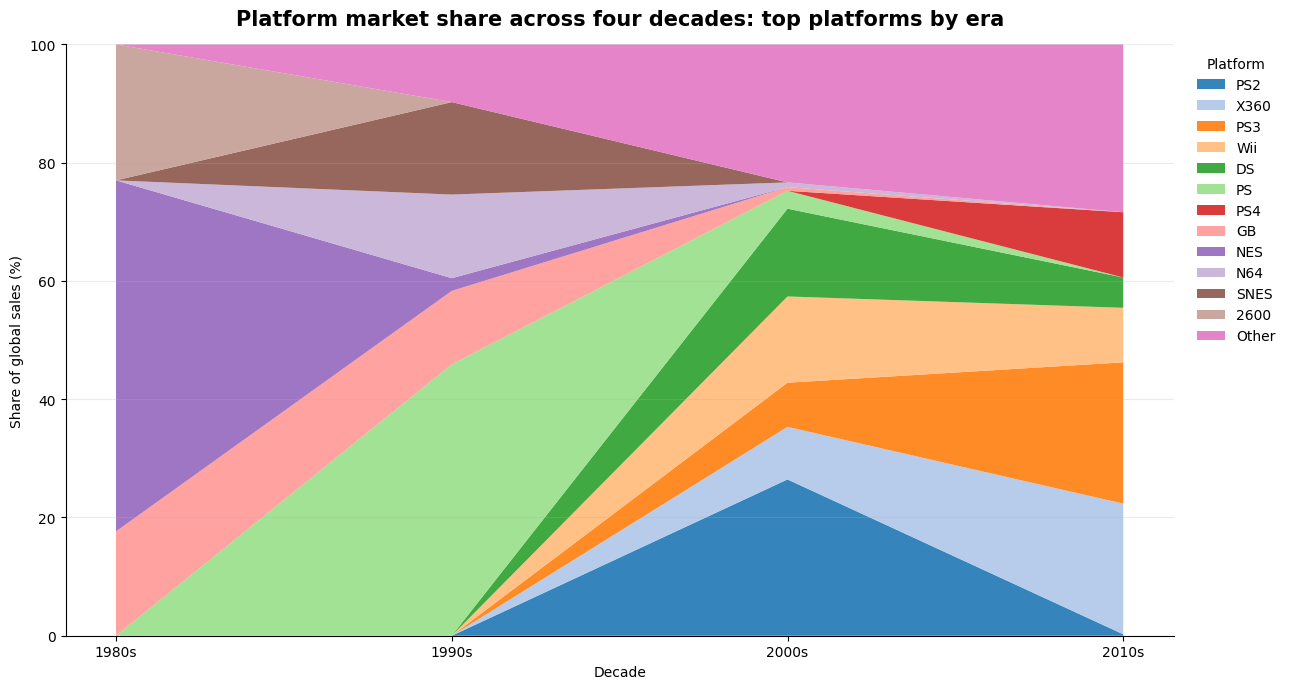

In [20]:
# leading platforms from each decade, with smaller platforms combined as other
platform_totals = q1.groupby("platform")["platform_sales_m"].sum().sort_values(ascending=False)
decade_leaders = (
    q1.sort_values(["decade", "platform_sales_m"], ascending=[True, False])
    .groupby("decade")
    .head(3)["platform"]
    .unique()
    .tolist()
)
top_platforms = platform_totals.loc[decade_leaders].sort_values(ascending=False).index.tolist()
platform_pivot = q1.pivot(index="decade", columns="platform", values="market_share_pct").fillna(0)
platform_plot = platform_pivot.reindex(columns=top_platforms, fill_value=0)
platform_plot["Other"] = (100 - platform_plot.sum(axis=1)).clip(lower=0)

fig, ax = plt.subplots(figsize=(13, 7))
stack_colors = list(plt.get_cmap("tab20").colors[:len(platform_plot.columns)])
ax.stackplot(
    platform_plot.index.astype(int),
    *[platform_plot[column].values for column in platform_plot.columns],
    labels=platform_plot.columns,
    colors=stack_colors,
    alpha=0.9,
)
ax.set_title("Platform market share across four decades: top platforms by era", pad=14, fontsize=15)
ax.set_xlabel("Decade")
ax.set_ylabel("Share of global sales (%)")
ax.set_xticks(platform_plot.index)
ax.set_xticklabels([f"{int(year)}s" for year in platform_plot.index])
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, title="Platform")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

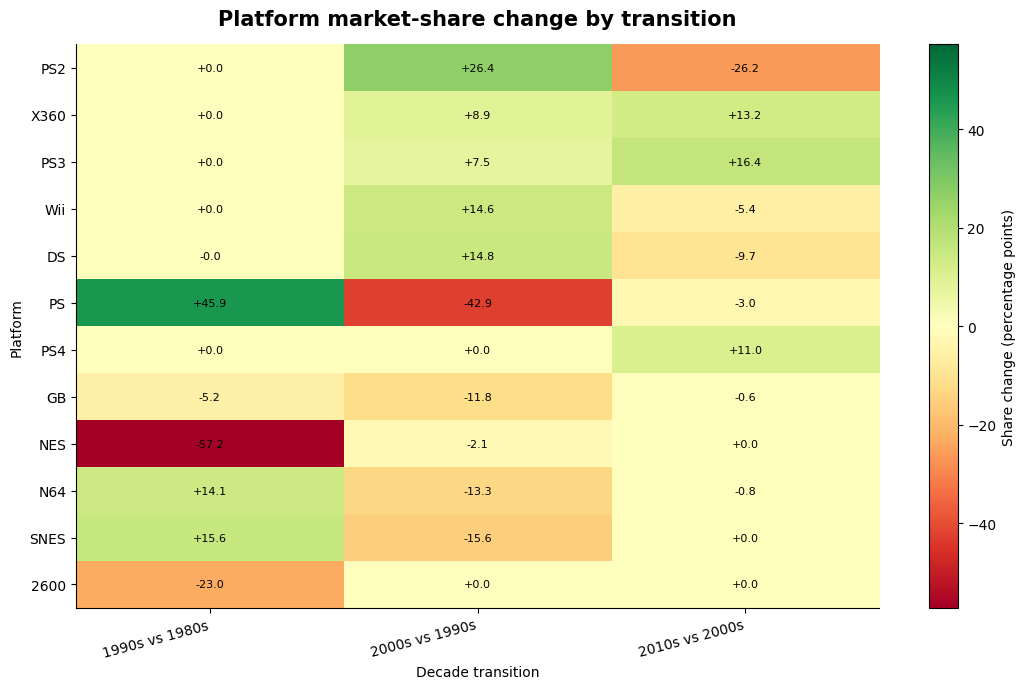

In [21]:
# platform share movement across consecutive decades
platform_change = q4.pivot(index="platform", columns="decade", values="share_change_pp").fillna(0)
decade_top_three = (
    q1.sort_values(["decade", "platform_sales_m"], ascending=[True, False])
    .groupby("decade")
    .head(3)["platform"]
    .unique()
    .tolist()
)
change_platforms = platform_totals.loc[decade_top_three].sort_values(ascending=False).index.tolist()
change_plot = platform_change.reindex(change_platforms)
change_plot = change_plot.rename(columns={1990: "1990s vs 1980s", 2000: "2000s vs 1990s", 2010: "2010s vs 2000s"})

limit = float(np.abs(change_plot.to_numpy()).max())
fig, ax = plt.subplots(figsize=(11, 7))
heatmap = ax.imshow(
    change_plot.to_numpy(),
    cmap="RdYlGn",
    aspect="auto",
    vmin=-limit,
    vmax=limit,
)
ax.set_title("Platform market-share change by transition", pad=14, fontsize=15)
ax.set_xlabel("Decade transition")
ax.set_ylabel("Platform")
ax.set_xticks(range(len(change_plot.columns)))
ax.set_xticklabels(change_plot.columns, rotation=15, ha="right")
ax.set_yticks(range(len(change_plot.index)))
ax.set_yticklabels(change_plot.index)
for row_index in range(change_plot.shape[0]):
    for column_index in range(change_plot.shape[1]):
        value = change_plot.iloc[row_index, column_index]
        ax.text(column_index, row_index, f"{value:+.1f}", ha="center", va="center", fontsize=8)
colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Share change (percentage points)")
fig.tight_layout()
plt.show()

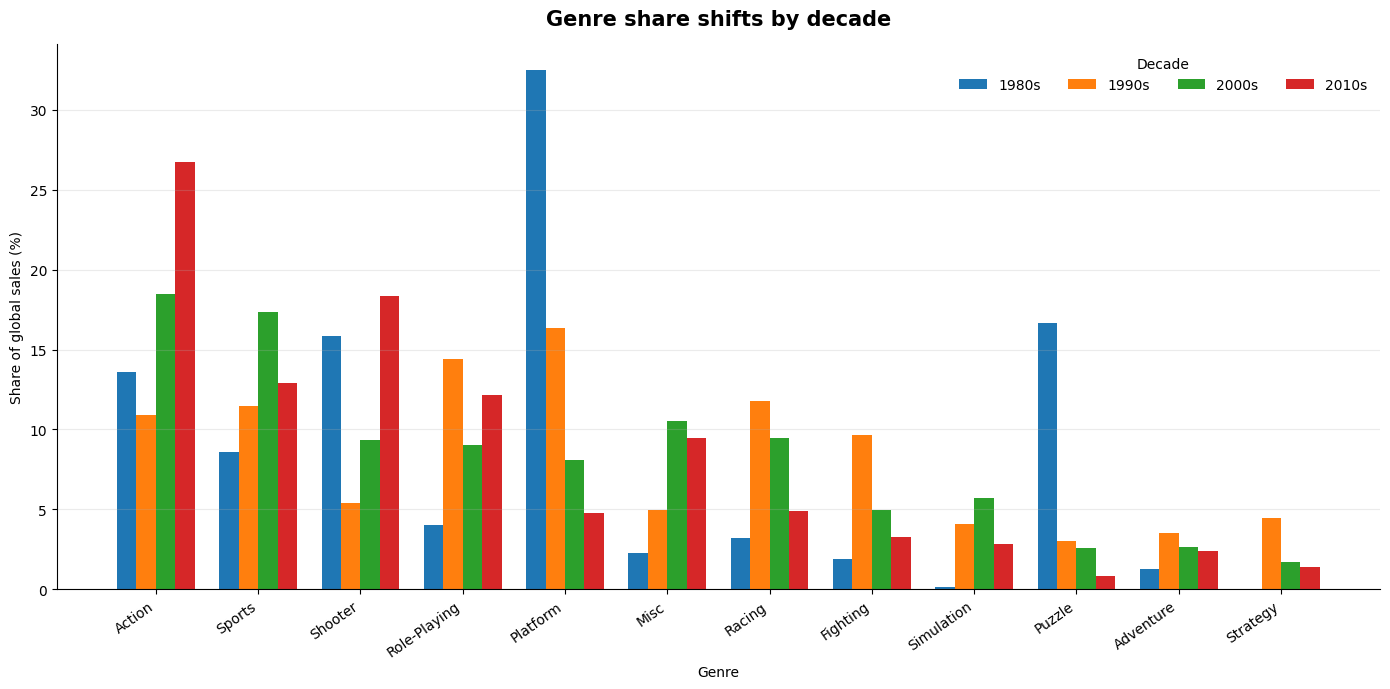

In [22]:
# global genre share by decade
genre_order = (
    q6.groupby("genre")["genre_sales_m"]
    .sum()
    .sort_values(ascending=False)
    .index
    .tolist()
)
genre_pivot = q6.pivot(index="genre", columns="decade", values="genre_share_pct").fillna(0)
genre_pivot = genre_pivot.reindex(genre_order)
decades = sorted(q6["decade"].unique())

fig, ax = plt.subplots(figsize=(14, 7))
bar_width = 0.19
positions = np.arange(len(genre_pivot.index))
genre_colors = list(plt.get_cmap("tab10").colors)
for index, decade in enumerate(decades):
    offsets = positions + (index - (len(decades) - 1) / 2) * bar_width
    ax.bar(offsets, genre_pivot[decade].values, width=bar_width, label=f"{decade}s", color=genre_colors[index])

ax.set_title("Genre share shifts by decade", pad=14, fontsize=15)
ax.set_xlabel("Genre")
ax.set_ylabel("Share of global sales (%)")
ax.set_xticks(positions)
ax.set_xticklabels(genre_pivot.index, rotation=35, ha="right")
ax.legend(title="Decade", frameon=False, ncol=4)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

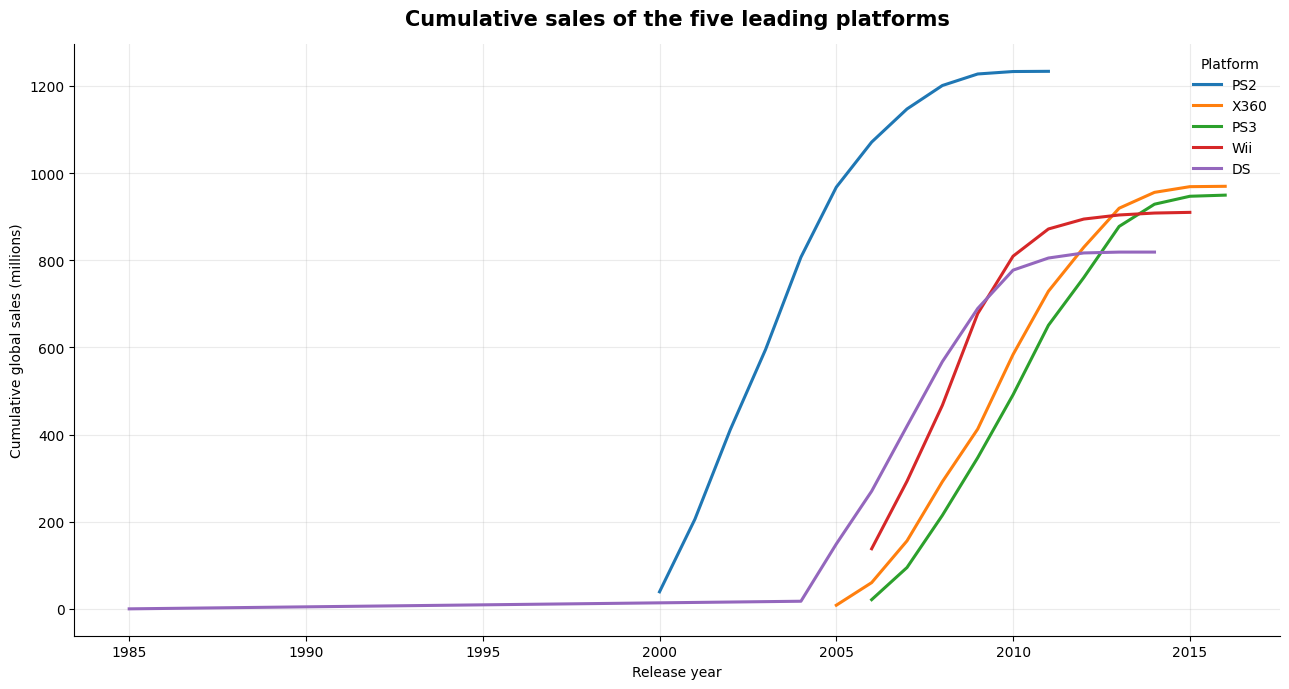

In [23]:
# cumulative sales for the five platforms with the highest lifetime sales
top_five_all_time = platform_lifetime_sales.head(5)["platform"].tolist()
cumulative_top_five = q5[q5["platform"].isin(top_five_all_time)].pivot(
    index="year",
    columns="platform",
    values="cumulative_sales_m",
)

fig, ax = plt.subplots(figsize=(13, 7))
line_colors = list(plt.get_cmap("tab10").colors)
for index, platform in enumerate(top_five_all_time):
    series = cumulative_top_five[platform].dropna()
    ax.plot(series.index, series.values, linewidth=2.2, label=platform, color=line_colors[index])

ax.set_title("Cumulative sales of the five leading platforms", pad=14, fontsize=15)
ax.set_xlabel("Release year")
ax.set_ylabel("Cumulative global sales (millions)")
ax.legend(frameon=False, title="Platform")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

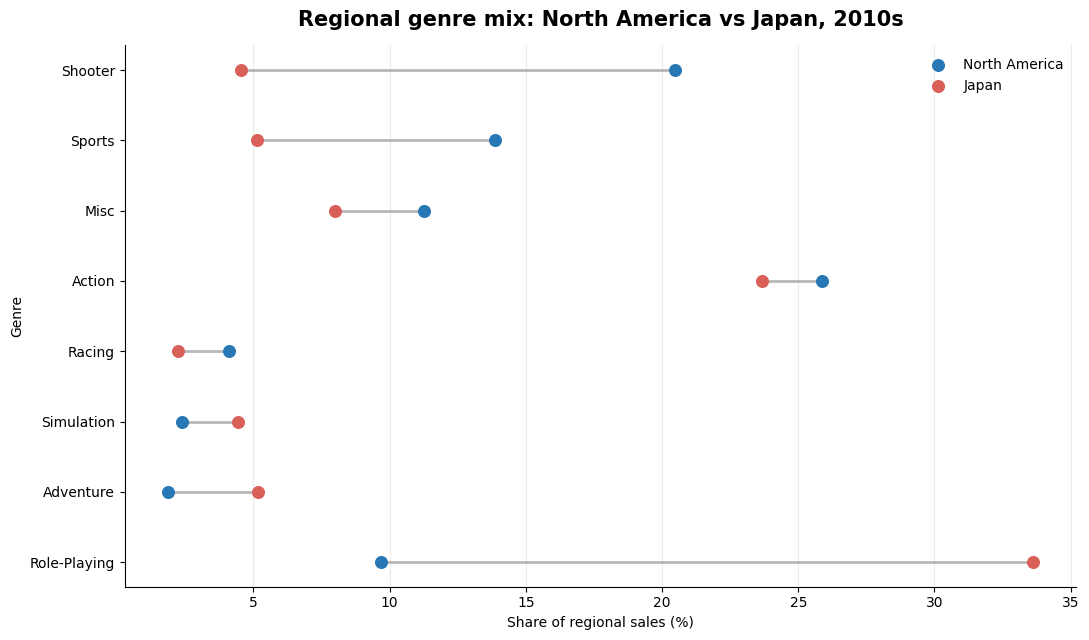

In [24]:
# north american and japanese genre shares in the 2010s
regional_2010s = (
    q8[q8["decade"] == 2010]
    .assign(absolute_gap=lambda frame: frame["na_minus_jp_pp"].abs())
    .sort_values("absolute_gap", ascending=False)
    .head(8)
    .sort_values("na_minus_jp_pp")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(11, 6.5))
y_positions = np.arange(len(regional_2010s))
for index, row in regional_2010s.iterrows():
    ax.plot(
        [row["na_share_pct"], row["jp_share_pct"]],
        [index, index],
        color="0.72",
        linewidth=2,
        zorder=1,
    )
ax.scatter(regional_2010s["na_share_pct"], y_positions, s=70, label="North America", color="#2878B5", zorder=2)
ax.scatter(regional_2010s["jp_share_pct"], y_positions, s=70, label="Japan", color="#D95F59", zorder=2)
ax.set_title("Regional genre mix: North America vs Japan, 2010s", pad=14, fontsize=15)
ax.set_xlabel("Share of regional sales (%)")
ax.set_ylabel("Genre")
ax.set_yticks(y_positions)
ax.set_yticklabels(regional_2010s["genre"])
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

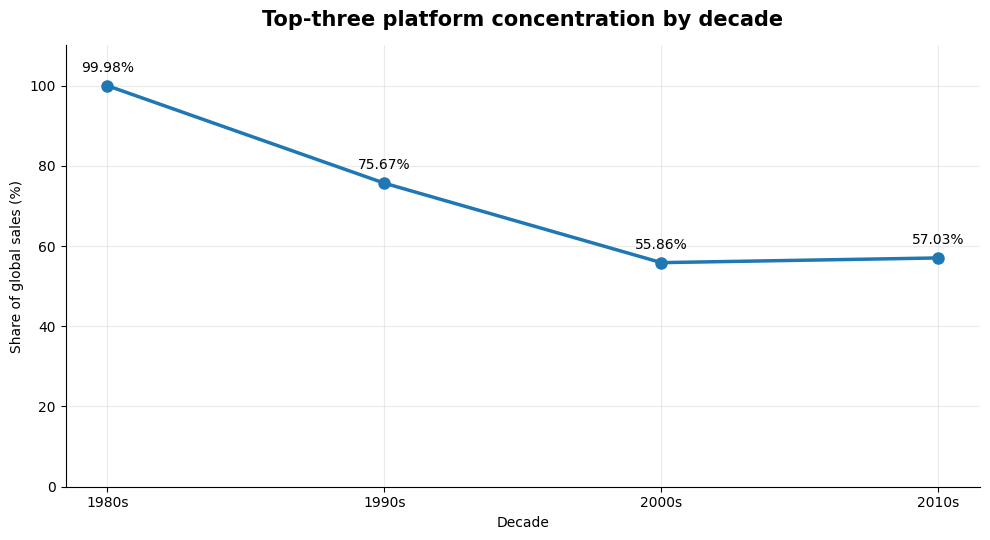

In [25]:
# share captured by the three leading platforms
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    q9["decade"].astype(int),
    q9["top_three_share_pct"],
    marker="o",
    linewidth=2.5,
    markersize=8,
)
for row in q9.itertuples(index=False):
    ax.annotate(
        f"{row.top_three_share_pct:.2f}%",
        (row.decade, row.top_three_share_pct),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )
ax.set_title("Top-three platform concentration by decade", pad=14, fontsize=15)
ax.set_xlabel("Decade")
ax.set_ylabel("Share of global sales (%)")
ax.set_xticks(q9["decade"].astype(int))
ax.set_xticklabels([f"{int(year)}s" for year in q9["decade"]])
ax.set_ylim(0, 110)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

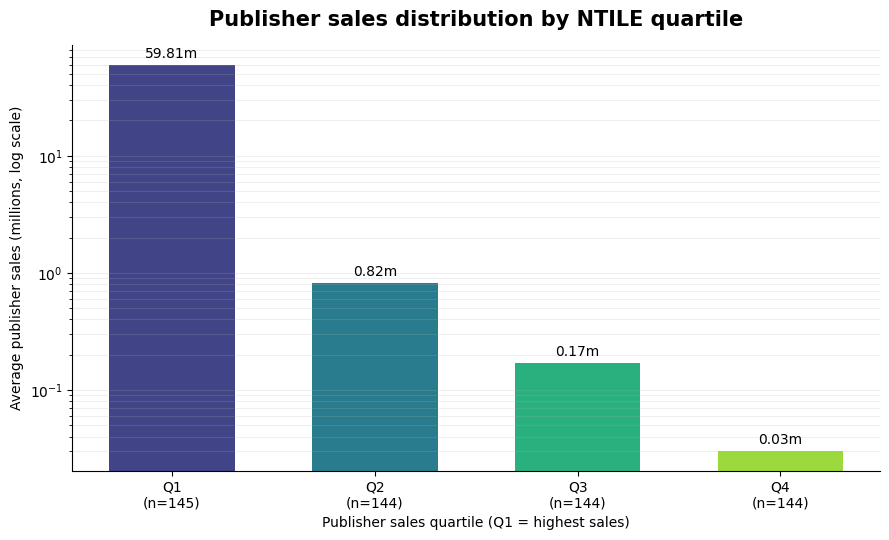

In [26]:
# average lifetime sales by publisher quartile
quartile_labels = [f"Q{int(value)}" for value in b1["sales_quartile"]]
fig, ax = plt.subplots(figsize=(9, 5.5))
quartile_colors = list(plt.get_cmap("viridis")(np.linspace(0.2, 0.85, len(b1))))
bars = ax.bar(quartile_labels, b1["avg_publisher_sales_m"], color=quartile_colors, width=0.62)
ax.set_yscale("log")
ax.set_title("Publisher sales distribution by NTILE quartile", pad=14, fontsize=15)
ax.set_xlabel("Publisher sales quartile (Q1 = highest sales)")
ax.set_ylabel("Average publisher sales (millions, log scale)")
ax.set_xticks(
    range(len(b1)),
    [f"Q{int(row.sales_quartile)}\n(n={int(row.publisher_count)})" for row in b1.itertuples(index=False)]
)
for bar, value in zip(bars, b1["avg_publisher_sales_m"]):
    ax.annotate(
        f"{value:.2f}m",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )
ax.grid(axis="y", which="both", alpha=0.2)
fig.tight_layout()
plt.show()

## Five-point market-shift narrative

The narrative combines the decade-level platform leaders, one-decade share changes, long-term genre shifts, regional differences, concentration metric, and publisher results. It describes patterns in reported sales; the dataset does not contain enough information to establish the causes of those patterns.

In [27]:
# values drawn directly from the executed sql result tables
first_decade = int(q1["decade"].min())
last_decade = int(q1["decade"].max())
first_leader = q1[q1["decade"] == first_decade].sort_values("market_share_pct", ascending=False).iloc[0]
last_leader = q1[q1["decade"] == last_decade].sort_values("market_share_pct", ascending=False).iloc[0]
largest_platform_gain = q4.loc[q4["share_change_pp"].idxmax()]
largest_platform_loss = q4.loc[q4["share_change_pp"].idxmin()]
largest_genre_gain = q7[q7["shift_type"] == "largest gain"].iloc[0]
largest_genre_loss = q7[q7["shift_type"] == "largest loss"].iloc[0]
regional_gap = q8[(q8["decade"] == 2010) & (q8["genre"] == "Role-Playing")].iloc[0]
concentration_change = float(q9.iloc[-1]["top_three_share_pct"] - q9.iloc[0]["top_three_share_pct"])

print("Platform leadership and turnover")
for row in platform_leaders.itertuples(index=False):
    print(f"{int(row.decade)}s: {row.platform} led with {row.market_share_pct:.2f}% of global sales.")
print(
    f"The largest single-transition gain was PS at +{largest_platform_gain['share_change_pp']:.2f} pp; "
    f"the largest loss was NES at {largest_platform_loss['share_change_pp']:.2f} pp, both into the 1990s."
)

print("\nGenre mix")
print(
    f"{largest_genre_gain['genre']} gained {largest_genre_gain['share_change_pp']:.2f} pp "
    f"from {largest_genre_gain['first_decade_share_pct']:.2f}% to {largest_genre_gain['final_decade_share_pct']:.2f}%."
)
print(
    f"{largest_genre_loss['genre']} lost {abs(largest_genre_loss['share_change_pp']):.2f} pp "
    f"from {largest_genre_loss['first_decade_share_pct']:.2f}% to {largest_genre_loss['final_decade_share_pct']:.2f}%."
)

print("\nRegional preferences")
print(
    f"In the 2010s, Role-Playing represented {regional_gap['na_share_pct']:.2f}% of NA sales "
    f"and {regional_gap['jp_share_pct']:.2f}% of JP sales ({regional_gap['na_minus_jp_pp']:.2f} pp NA minus JP)."
)
shooter_2010s = q8[(q8["decade"] == 2010) & (q8["genre"] == "Shooter")].iloc[0]
print(
    f"Shooter showed the opposite pattern: {shooter_2010s['na_share_pct']:.2f}% in NA "
    f"versus {shooter_2010s['jp_share_pct']:.2f}% in JP."
)

print("\nMarket concentration")
print(
    f"The top-three platform share moved from {q9.iloc[0]['top_three_share_pct']:.2f}% in the 1980s "
    f"to {q9.iloc[-1]['top_three_share_pct']:.2f}% in the 2010s ({concentration_change:+.2f} pp overall). "
    f"The lowest point was {q9.loc[q9['top_three_share_pct'].idxmin(), 'top_three_share_pct']:.2f}% in the 2000s."
)

print("\nPublisher leadership")
for row in q10.itertuples(index=False):
    print(f"{int(row.decade)}s: {row.publisher} led with {row.publisher_sales_m:.2f} million sales.")

print("\nInterpretation boundary")
print("The observed pattern is consistent with successive platform generations and a changing game mix, "
      "but sales totals alone cannot isolate hardware launches, exclusives, pricing, or consumer preferences as causes.")
print("The source ends in 2017, so the 2010s comparison is incomplete.")

Platform leadership and turnover
1980s: NES led with 59.36% of global sales.
1990s: PS led with 45.89% of global sales.
2000s: PS2 led with 26.43% of global sales.
2010s: PS3 led with 23.90% of global sales.
The largest single-transition gain was PS at +45.89 pp; the largest loss was NES at -57.20 pp, both into the 1990s.

Genre mix
Action gained 13.13 pp from 13.59% to 26.72%.
Platform lost 27.68 pp from 32.47% to 4.79%.

Regional preferences
In the 2010s, Role-Playing represented 9.67% of NA sales and 33.62% of JP sales (-23.95 pp NA minus JP).
Shooter showed the opposite pattern: 20.46% in NA versus 4.53% in JP.

Market concentration
The top-three platform share moved from 99.98% in the 1980s to 57.03% in the 2010s (-42.95 pp overall). The lowest point was 55.86% in the 2000s.

Publisher leadership
1980s: Nintendo led with 234.92 million sales.
1990s: Nintendo led with 364.56 million sales.
2000s: Nintendo led with 883.89 million sales.
2010s: Electronic Arts led with 360.92 million

## Interpretation boundaries

The dataset records reported unit sales, not revenue, profit, active users, or player retention. The 2010s decade is incomplete because the source ends in 2017. Publisher labels are missing for 58 source rows and are retained under `(unknown)`. Market-share movements describe the composition of the supplied dataset; they do not prove why consumer preferences or platform adoption changed.

In [28]:
# final execution and result-size check
assert len(query_results) == 13
assert all(not result.empty for result in query_results.values())
print(f"Completed SQL statements: {len(query_results)}")
print(f"Analysis rows: {len(prepared):,}")
print(f"Excluded source rows: {original_rows - len(prepared):,}")

Completed SQL statements: 13
Analysis rows: 16,326
Excluded source rows: 272
